# Synthetic Normal and AS heart sounds

This notebook demonstrates the Python implementation in `synthetic_pcg.py`.
Run cells in order from this folder. Synthesis is implemented in the `.py`
module; this notebook contains example calls and plotting code only.

The saved outputs show a controlled beat with and without an AS murmur,
complete 10-second recordings, and 3-second detail views. All examples are
synthetic illustrations; their appearance is not evidence of clinical validity.
No WAVs or full datasets are created by running this notebook.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from synthetic_pcg import (
    AS_CONFIG,
    COMMON_CONFIG,
    SAMPLE_RATE,
    SYNTHESIS_PROFILE,
    generate_beat,
    generate_recording,
)

print("Reference revision:", SYNTHESIS_PROFILE["reference_commit"])
print("Sampling rate:", SAMPLE_RATE, "Hz")
print("AS timing policy:", SYNTHESIS_PROFILE["as_timing"])

Reference revision: 1a5f600ce2a0a9e43514e20582da67081159a14a
Sampling rate: 8000 Hz
AS timing policy: reference


## One beat: isolate the murmur

Use the published base parameters without recording/beat perturbations.
The left column removes the murmur from the same generated beat, keeping
S1, S2, background and noise identical. The right column includes it.
These are raw components before recording-level normalization and smoothing.
The shaded interval is the reference murmur placement window, which can overlap
placed S1 because the reference computes the window from unplaced S1.

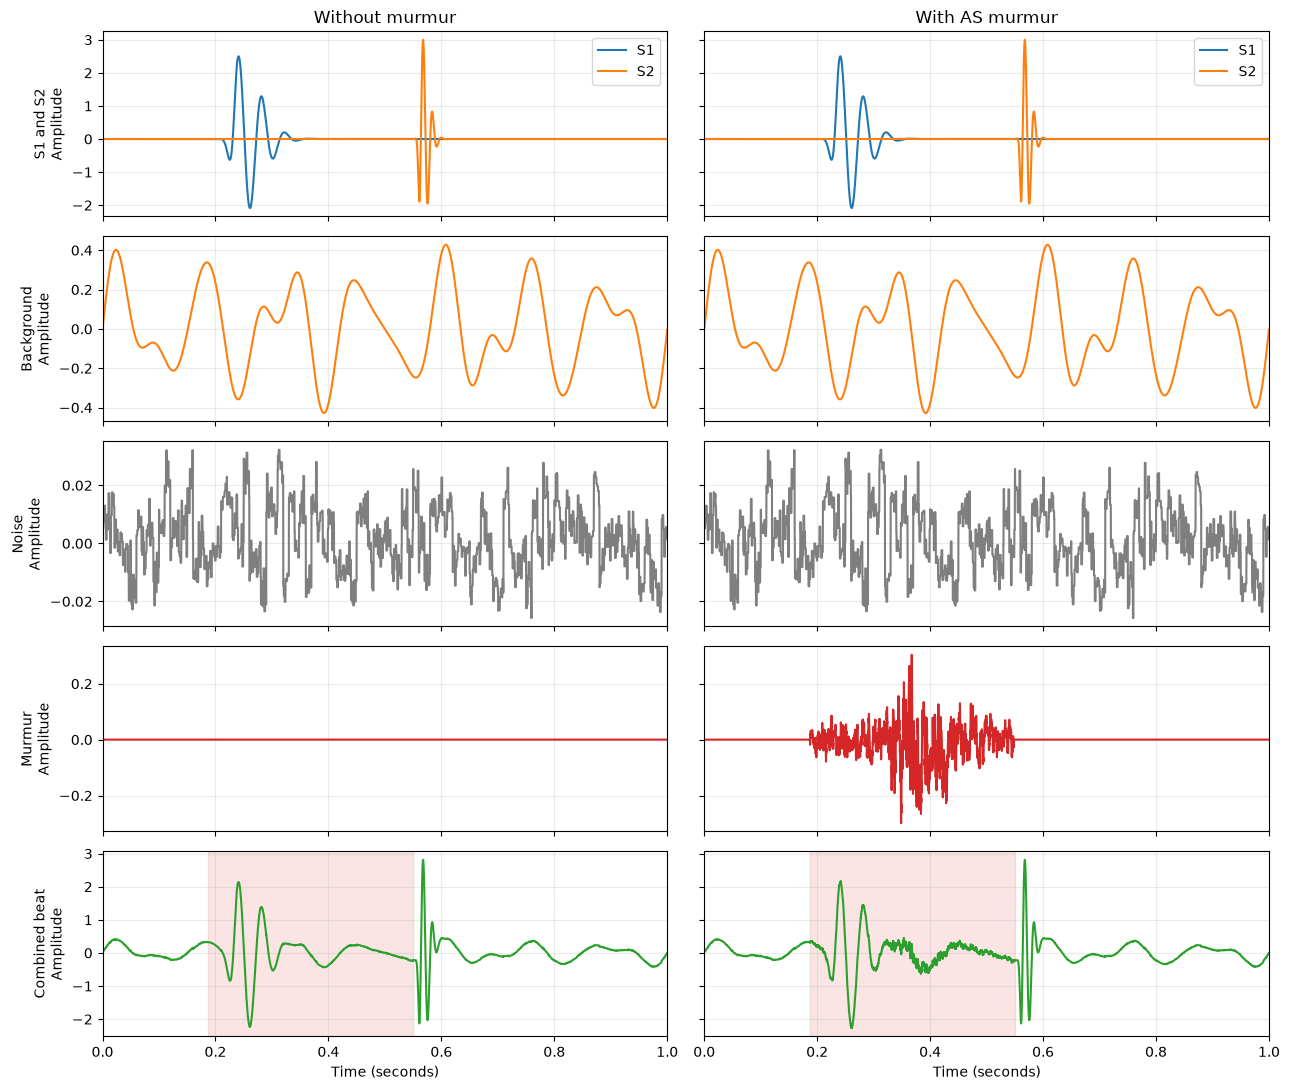

In [2]:
parameters = {
    name: specification["base"]
    for name, specification in {**COMMON_CONFIG, **AS_CONFIG}.items()
}
beat = generate_beat(
    "AS", parameters, rng=np.random.default_rng(42), timing="reference"
)
time = beat["time"]
start, end = beat["murmur_window"]

fig, axes = plt.subplots(5, 2, figsize=(13, 11), sharex=True, sharey="row")
for column, include_murmur in enumerate((False, True)):
    axes[0, column].plot(time, beat["s1"], label="S1")
    axes[0, column].plot(time, beat["s2"], label="S2")
    axes[0, column].legend(loc="upper right")
    axes[1, column].plot(time, beat["background"], color="tab:orange")
    axes[2, column].plot(time, beat["noise"], color="tab:gray")
    murmur = beat["murmur"] if include_murmur else np.zeros_like(time)
    axes[3, column].plot(time, murmur, color="tab:red")
    combined = beat["waveform"] if include_murmur else beat["baseline"]
    axes[4, column].plot(time, combined, color="tab:green")
    axes[4, column].axvspan(start, end, alpha=0.12, color="tab:red")
    axes[0, column].set_title("With AS murmur" if include_murmur else "Without murmur")
    axes[4, column].set_xlabel("Time (seconds)")

for row, label in enumerate(("S1 and S2", "Background", "Noise", "Murmur", "Combined beat")):
    axes[row, 0].set_ylabel(label + "\nAmplitude")
for axis in axes.flat:
    axis.grid(alpha=0.25)
    axis.set_xlim(0, parameters["duration"])
fig.tight_layout()
plt.show()

## Complete recordings

Generate two Normal and two AS recordings with the primary reference timing.
Each has 80,000 samples: 10 seconds at 8 kHz. Generation includes parameter
variation between recordings and beats, normalization, smoothing and cropping.
The same numeric seed across classes does not create identical baseline signals.

Normal, seed=11: (80000,), float32, beats generated=15
Normal, seed=42: (80000,), float32, beats generated=15
AS, seed=11: (80000,), float32, beats generated=15
AS, seed=42: (80000,), float32, beats generated=15


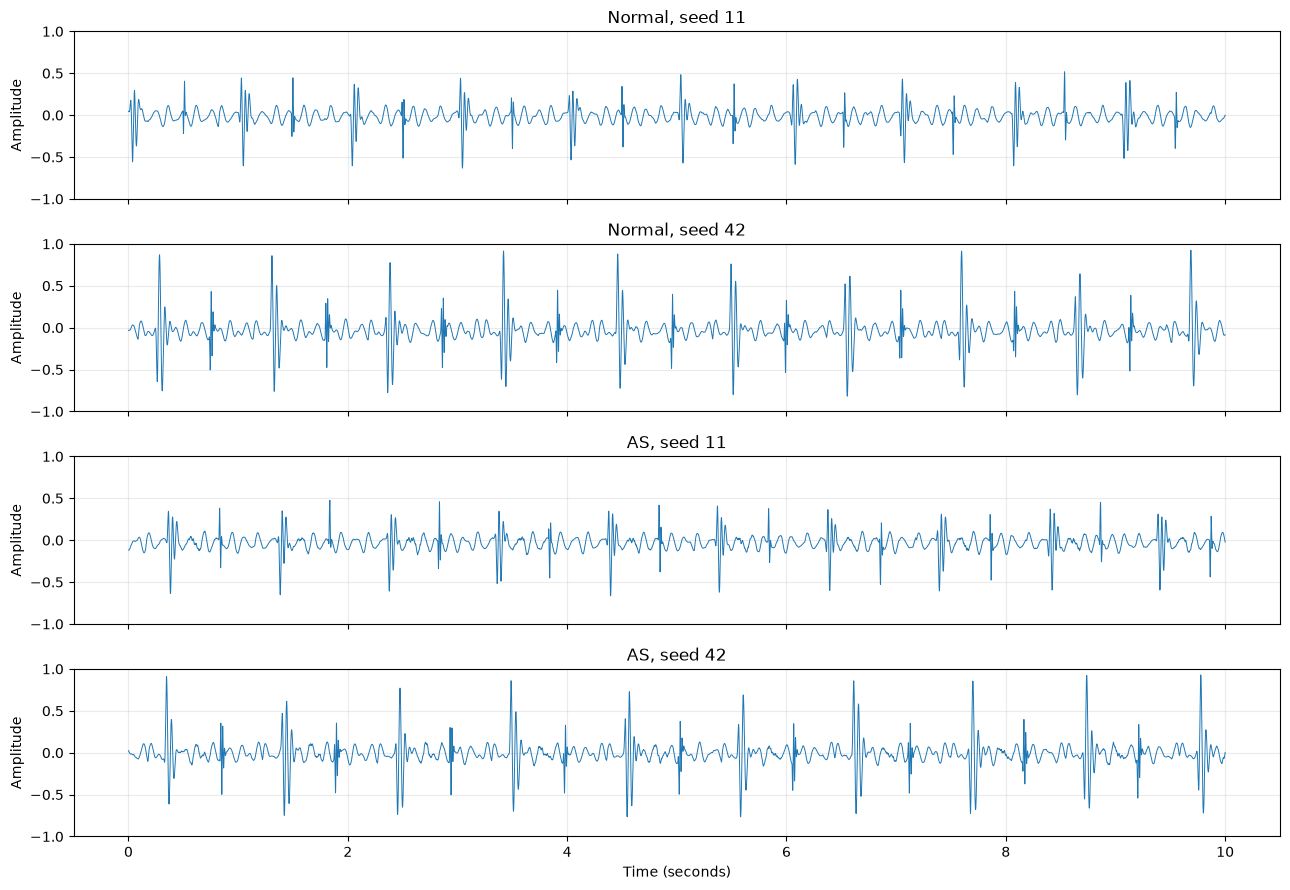

In [3]:
examples = []
for label in ("Normal", "AS"):
    for seed in (11, 42):
        waveform, metadata = generate_recording(label, seed=seed)
        examples.append((waveform, metadata))
        print(
            f"{label}, seed={seed}: {waveform.shape}, {waveform.dtype}, "
            f"beats generated={metadata['generated_beats']}"
        )

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True, sharey=True)
for axis, (waveform, metadata) in zip(axes, examples):
    time = np.arange(len(waveform)) / metadata["sample_rate"]
    axis.plot(time, waveform, linewidth=0.7)
    axis.set_title(f"{metadata['label']}, seed {metadata['seed']}")
    axis.set_ylabel("Amplitude")
    axis.set_ylim(-1, 1)
    axis.grid(alpha=0.25)
axes[-1].set_xlabel("Time (seconds)")
fig.tight_layout()
plt.show()

## Three-second detail

This time span matches the waveform examples in paper Figures 4-5.
The paper uses different realizations; this is a visual illustration, not an
exact recreation of those figure arrays.

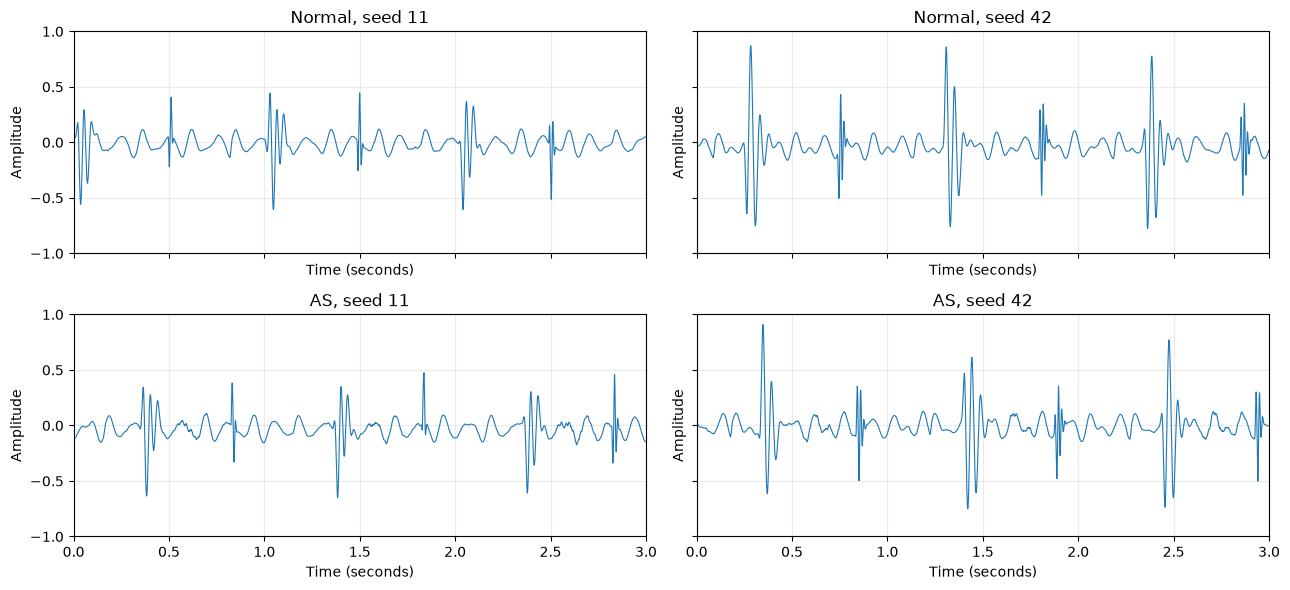

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True, sharey=True)
for axis, (waveform, metadata) in zip(axes.flat, examples):
    count = 3 * metadata["sample_rate"]
    time = np.arange(count) / metadata["sample_rate"]
    axis.plot(time, waveform[:count], linewidth=0.8)
    axis.set_title(f"{metadata['label']}, seed {metadata['seed']}")
    axis.set_xlabel("Time (seconds)")
    axis.set_ylabel("Amplitude")
    axis.set_ylim(-1, 1)
    axis.set_xlim(0, 3)
    axis.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Batch generation and PyHealth

See `README.md` and `EXPERIMENT_POLICY.md` for the selected five-run policy,
configurable run plans, and pilot/full generation commands using
`generate_dataset_cli.py`, manifest inspection and optional PyHealth loading.
The notebook deliberately generates only four recordings in memory.

Normal is label `0`; AS is label `1`. The generator does not implement AR or MR.
The reference uses a different random-number implementation, so outputs are
not bitwise identical to its recordings. Refer to the README for differences
and the current experimental scope.

Paper: [Nonaka et al., PMLR 297 (2026)](https://proceedings.mlr.press/v297/nonaka26a.html).
Reference: [seitalab/SynPCG](https://github.com/seitalab/SynPCG), revision
`1a5f600ce2a0a9e43514e20582da67081159a14a`.

## Optional: create the five-run plan

Default policy: reuse the existing 12,000 recordings; retain the first split and
reshuffle four times with 5,000 training / 1,000 validation recordings per class.
The cell below is disabled by default. Enable it only after choosing the source
manifest and a new output path. It writes a JSON plan, not new audio.

Counts are inferred from the source manifest. Customize `n_runs`, seed lists,
counts and `preserve_first` as described in the README. Model training seeds
are recorded here and must be applied by the later training runner.


In [5]:
from synthetic_splits import create_split_plan

CREATE_SPLIT_PLAN = False
SOURCE_MANIFEST = Path("../synthetic_data/paper_seed42/manifest.csv")
PLAN_PATH = Path("synthetic_runs/five_runs.json")
SPLIT_OPTIONS = {
    "n_runs": 5,
    "preserve_first": True,
    "split_seeds": [42, 43, 44, 45],
    "training_seeds": [0, 1, 2, 3, 4],
}

if CREATE_SPLIT_PLAN:
    plan_path = create_split_plan(SOURCE_MANIFEST, PLAN_PATH, **SPLIT_OPTIONS)
    print("Saved run assignments:", plan_path)
else:
    print("Plan creation disabled; edit paths/options and enable when ready.")


Plan creation disabled; edit paths/options and enable when ready.
